# EDA — Eksplorasi Data ISPU Jakarta

Grafik untuk laporan bagian data. Input: "data/processed/data_siap.csv" (hasil "prepare_data.ipynb"). Output: 5 gambar PNG di "reports/figures/".

**Cara menjalankan:** jalankan "prepare_data.ipynb" dulu, lalu di sini **Restart → Run All**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from config import DATA_SIAP, DATA_RAW_DIR, DATA_RAW_POLA, FOLDER_GRAFIK, TARGET, kategori_ispu

WARNA_UTAMA = "steelblue"
WARNA_BATAS = "orange"

plt.rcParams["axes.axisbelow"] = True
FOLDER_GRAFIK.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(DATA_SIAP, parse_dates=["tanggal"])
print(data.shape)
data.head()

(22835, 7)


,tanggal,stasiun,ispu_hari_ini,ispu_kemarin,bulan,hari,ispu_besok
0,2010-01-02,DKI1 (Bunderan HI),33,73,1,5,27
1,2010-01-03,DKI1 (Bunderan HI),27,33,1,6,22
2,2010-01-04,DKI1 (Bunderan HI),22,27,1,0,25
3,2010-01-05,DKI1 (Bunderan HI),25,22,1,1,30
4,2010-01-06,DKI1 (Bunderan HI),30,25,1,2,41


## 1. Tren ISPU 2010–2025

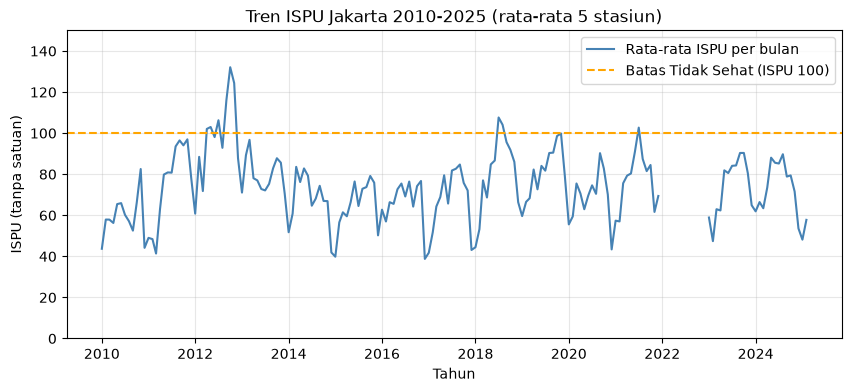

In [2]:
rata2_bulanan = data.set_index("tanggal")["ispu_hari_ini"].resample("MS").mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(rata2_bulanan.index, rata2_bulanan.values, color=WARNA_UTAMA, label="Rata-rata ISPU per bulan")
ax.axhline(100, color=WARNA_BATAS, linestyle="--", label="Batas Tidak Sehat (ISPU 100)")
ax.set_xlabel("Tahun")
ax.set_ylabel("ISPU (tanpa satuan)")
ax.set_ylim(0, 150)
ax.set_title("Tren ISPU Jakarta 2010-2025 (rata-rata 5 stasiun)")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
fig.savefig(FOLDER_GRAFIK / "1_tren_ispu_bulanan.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
## 2. Pola musiman per bulan

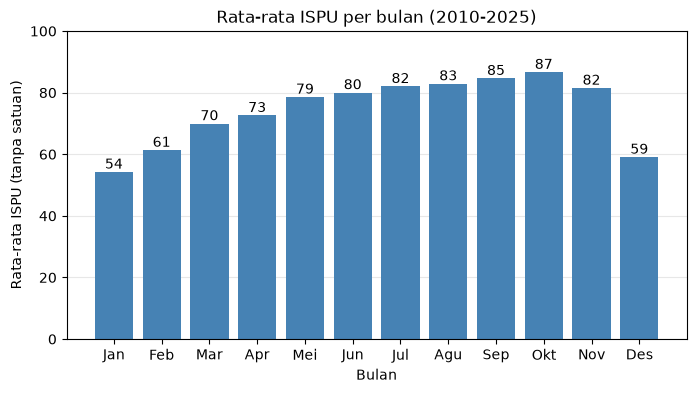

Bulan tertinggi: Okt 87
Bulan terendah : Jan 54


In [4]:
nama_bulan = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
rata2_per_bulan = data.groupby("bulan")["ispu_hari_ini"].mean()

fig, ax = plt.subplots(figsize=(8, 4))
batang = ax.bar(nama_bulan, rata2_per_bulan.values, color=WARNA_UTAMA)
ax.bar_label(batang, fmt="%.0f")
ax.set_xlabel("Bulan")
ax.set_ylabel("Rata-rata ISPU (tanpa satuan)")
ax.set_ylim(0, 100)
ax.set_title("Rata-rata ISPU per bulan (2010-2025)")
ax.grid(axis="y", alpha=0.3)
fig.savefig(FOLDER_GRAFIK / "2_pola_musiman.png", dpi=150, bbox_inches="tight")
plt.show()

print("Bulan tertinggi:", nama_bulan[rata2_per_bulan.idxmax() - 1], round(rata2_per_bulan.max()))
print("Bulan terendah :", nama_bulan[rata2_per_bulan.idxmin() - 1], round(rata2_per_bulan.min()))

## 3. ISPU hari ini vs besok

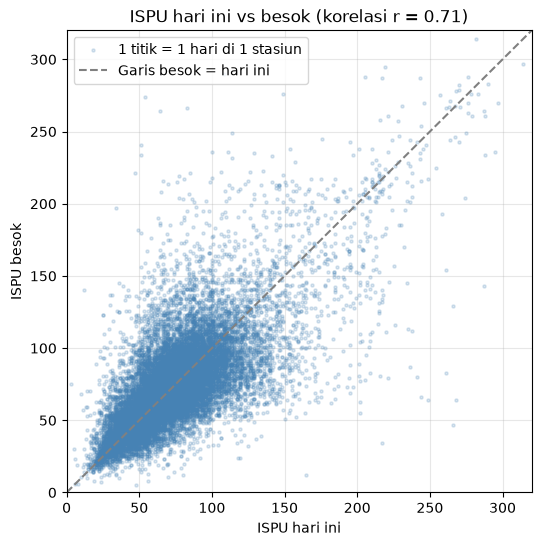

Korelasi ISPU besok dengan hari ini: 0.71
Korelasi ISPU besok dengan kemarin : 0.61


In [5]:
korelasi_hari_ini = data["ispu_hari_ini"].corr(data[TARGET])
korelasi_kemarin = data["ispu_kemarin"].corr(data[TARGET])

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(data["ispu_hari_ini"], data[TARGET], s=5, alpha=0.2, color=WARNA_UTAMA, label="1 titik = 1 hari di 1 stasiun")
ax.plot([0, 320], [0, 320], color="gray", linestyle="--", label="Garis besok = hari ini")
ax.set_xlim(0, 320)
ax.set_ylim(0, 320)
ax.set_xlabel("ISPU hari ini")
ax.set_ylabel("ISPU besok")
ax.set_title(f"ISPU hari ini vs besok (korelasi r = {korelasi_hari_ini:.2f})")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
fig.savefig(FOLDER_GRAFIK / "3_hari_ini_vs_besok.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Korelasi ISPU besok dengan hari ini: {korelasi_hari_ini:.2f}")
print(f"Korelasi ISPU besok dengan kemarin : {korelasi_kemarin:.2f}")

## 4. Distribusi kategori ISPU besok

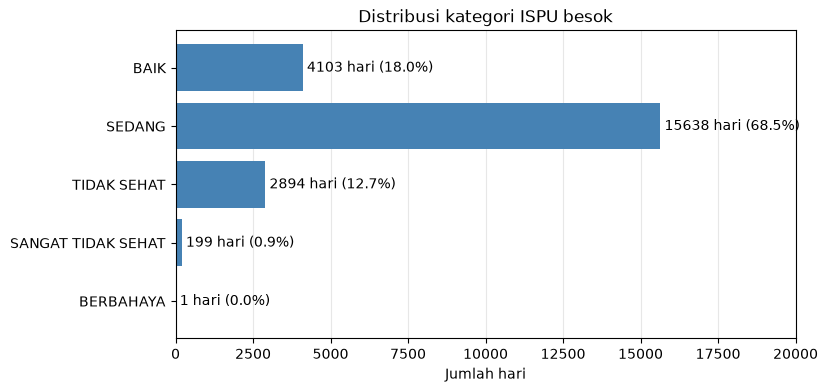

ispu_besok
BAIK                   4103
SEDANG                15638
TIDAK SEHAT            2894
SANGAT TIDAK SEHAT      199
BERBAHAYA                 1
Name: count, dtype: int64


In [6]:
urutan_kategori = ["BAIK", "SEDANG", "TIDAK SEHAT", "SANGAT TIDAK SEHAT", "BERBAHAYA"]
kategori_besok = data[TARGET].map(kategori_ispu)
jumlah_per_kategori = kategori_besok.value_counts().reindex(urutan_kategori, fill_value=0)
persen = jumlah_per_kategori / len(data) * 100

fig, ax = plt.subplots(figsize=(8, 4))
batang = ax.barh(urutan_kategori, jumlah_per_kategori.values, color=WARNA_UTAMA)
ax.bar_label(batang, labels=[f"{n} hari ({p:.1f}%)" for n, p in zip(jumlah_per_kategori, persen)], padding=3)
ax.invert_yaxis()
ax.set_xlabel("Jumlah hari")
ax.set_xlim(0, 20000)
ax.set_title("Distribusi kategori ISPU besok")
ax.grid(axis="x", alpha=0.3)
fig.savefig(FOLDER_GRAFIK / "4_distribusi_kategori.png", dpi=150, bbox_inches="tight")
plt.show()

print(jumlah_per_kategori)

## 5. Ketersediaan data per stasiun per tahun

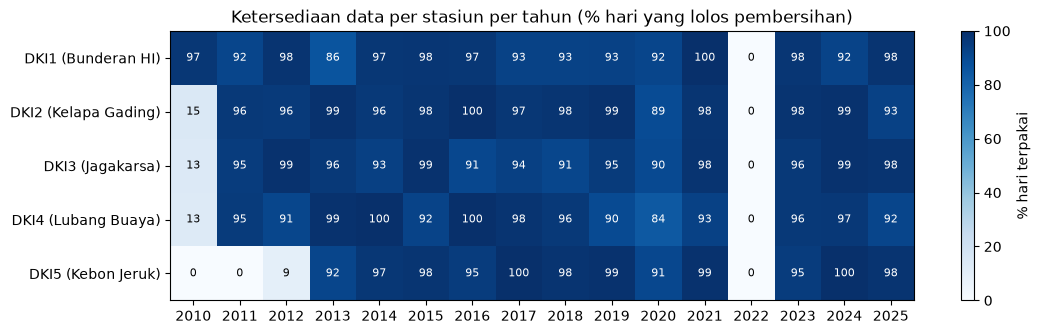

In [7]:
hari_per_tahun = pd.Series(pd.date_range("2010-01-01", "2025-02-28")).dt.year.value_counts().sort_index()

terpakai = data.groupby(["stasiun", data["tanggal"].dt.year]).size().unstack(fill_value=0)
terpakai = terpakai.reindex(columns=hari_per_tahun.index, fill_value=0)
persen_terpakai = terpakai / hari_per_tahun * 100

fig, ax = plt.subplots(figsize=(12, 3.5))
gambar = ax.imshow(persen_terpakai, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(persen_terpakai.columns)), persen_terpakai.columns)
ax.set_yticks(range(len(persen_terpakai.index)), persen_terpakai.index)
ax.grid(False)
for i in range(persen_terpakai.shape[0]):
    for j in range(persen_terpakai.shape[1]):
        nilai = persen_terpakai.iloc[i, j]
        ax.text(j, i, f"{nilai:.0f}", ha="center", va="center", fontsize=8,
                color="white" if nilai > 60 else "black")
fig.colorbar(gambar, ax=ax, label="% hari terpakai")
ax.set_title("Ketersediaan data per stasiun per tahun (% hari yang lolos pembersihan)")
fig.savefig(FOLDER_GRAFIK / "5_ketersediaan_data.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Pola per hari dalam seminggu

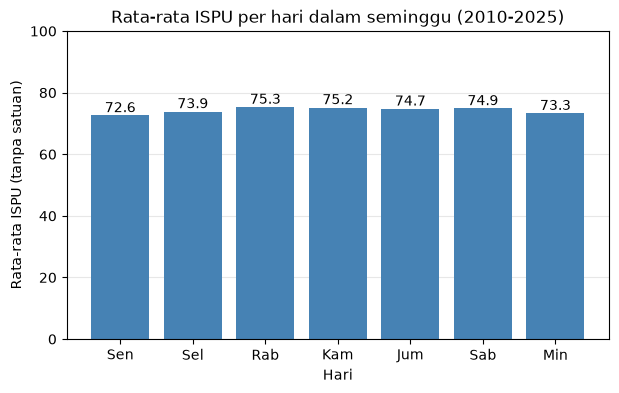

Selisih hari tertinggi dan terendah: 2.7


In [8]:
nama_hari = ["Sen", "Sel", "Rab", "Kam", "Jum", "Sab", "Min"]
rata2_per_hari = data.groupby("hari")["ispu_hari_ini"].mean()

fig, ax = plt.subplots(figsize=(7, 4))
batang = ax.bar(nama_hari, rata2_per_hari.values, color=WARNA_UTAMA)
ax.bar_label(batang, fmt="%.1f")
ax.set_xlabel("Hari")
ax.set_ylabel("Rata-rata ISPU (tanpa satuan)")
ax.set_ylim(0, 100)
ax.set_title("Rata-rata ISPU per hari dalam seminggu (2010-2025)")
ax.grid(axis="y", alpha=0.3)
fig.savefig(FOLDER_GRAFIK / "6_pola_hari.png", dpi=150, bbox_inches="tight")
plt.show()

print("Selisih hari tertinggi dan terendah:", round(rata2_per_hari.max() - rata2_per_hari.min(), 1))